# Auxotrophies and minimal medium

In [ ]:
import reframed
from reframed.cobra import auxotrophy
import pandas as pd
import numpy as np
import seaborn as sns
from collections import OrderedDict
import sys

from matplotlib.pyplot import gcf

sys.path.append("../functions/")
from simulation.minimal_medium import make_minimal_media_df
from simulation.minimal_medium import minimal_medium
import simulation.general as general

In [3]:
%load_ext autoreload
%autoreload 2

**Set gurobi as default solver**

In [4]:
reframed.set_default_solver("gurobi")

**Load other data (E. coli)**

In [5]:
relative_abundance_ecoli = pd.read_csv("../data/Guillen2021/relative_abundance.csv",index_col=0)
relative_abundance_ecoli.index = relative_abundance_ecoli.index.map(lambda x:x if x!="yhhK" else "panZ")

gene_id2name = pd.read_csv("../data/Guillen2021/generated/gene_id2name.tsv",sep="\t")

**Load models**

*E. coli mutants  (top 7) and (all 38)*

In [6]:
RA_ecoli_mean = relative_abundance_ecoli.T.mean().sort_values(ascending=False)

In [7]:
models_ecoli = general.load_models_guillen2021(all_38_strains=True)
models_ecoli_top7 = general.load_models_guillen2021(all_38_strains=False)


INFO     | Loading models from Guillen et al (2021)...
INFO     | Loading models from Guillen et al (2021)...


*Gut microbiome members*

In [8]:
models_gut = general.load_models_venturelli2018()


INFO     | Loading models from Venturelli et al (2018)...


**Load media**

*For E. coli mutants (LB medium to see auxotrophies)*

In [9]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = list(media_db[media_db.medium=="LB"].compound.values)
compounds.append("btn") # biot members are auxotrophic to biotin which was not in LB-medium. 
compounds.append("mmet") # metE and metH double mutant has been shown to be dependent on mmet (S-Methylmethionine). metH is missing in the model!
compounds.append("26dap__M") # meso-DAP. Essential part of cell wall in gram-negative bacteria...
env_ecoli_lb = reframed.Environment.from_compounds(compounds)

*For gut microbiome members*

In [10]:
media_db_gut = pd.read_csv("../data/Venturelli2018/generated/media_db.tsv",sep="\t")
reactions = media_db_gut[media_db_gut.medium=="LB_extend"].compound.values
reactions = [rxn.replace("91","40").replace("93","41") for rxn in reactions]

env_gut_single = reframed.Environment.from_reactions(reactions)

**Translation dicts**

In [11]:
mets_id_ag = []
mets_id_bigg = []
ex_rxns_ag = []
for model in models_gut.values():
    for rxn in model.get_exchange_reactions():
        if "R_EX_" not in rxn:
            continue
        met_id_ag = model.reactions[rxn].get_substrates()[0]
        mets_id_ag.append(met_id_ag)
        met_id_bigg = model.metabolites[met_id_ag].metadata["bigg.metabolite"][0]
        mets_id_bigg.append(met_id_bigg)
        ex_rxns_ag.append(rxn)
    
met2ex = dict(zip(mets_id_bigg,ex_rxns_ag))

### Find minimal medium

### Plot solutions

In [24]:

minimal_media_df_ecoli = pd.read_csv("../output/Guillen2021/minimal_media.tsv",sep="\t",index_col=0)

minimal_media_df_gut = pd.read_csv("../output/Venturelli2018/minimal_media.tsv",sep="\t",index_col=0)


**Remove results for less interesting compounds**: *compounds that few members have auxotrophy for/compounds all members have auxotrophy for, and minerals etc (from M9 medium)*

In [25]:
m9_mets = media_db[media_db.medium=="M9"].compound.values
m9_rxns = ["R_EX_"+met+"_e" for met in m9_mets]
m9_rxns_gut = ["R_EX_"+met+"__40__e__41__" for met in m9_mets]

In [27]:
minimal_media_df_ecoli_plot = minimal_media_df_ecoli.copy()
minimal_media_df_ecoli_plot = minimal_media_df_ecoli_plot[~minimal_media_df_ecoli_plot.index.isin(m9_rxns)]

minimal_media_df_gut_plot = minimal_media_df_gut.copy()
minimal_media_df_gut_plot = minimal_media_df_gut_plot[~minimal_media_df_gut_plot.index.isin(m9_rxns_gut)]

**Define color palette**

In [28]:
bigg_met2chebi_class = pd.read_csv("../../../GEMs_from_MAGs/output/met_chebi_class.tsv",sep="\t",index_col=0)

met2chebi = bigg_met2chebi_class["self defined super class"].to_dict()
met2chebi = {key[2:-2]:value for key,value in met2chebi.items()}

agoraEx2chebi = {met2ex[key]: value for key, value in met2chebi.items() if key in met2ex.keys()}

for value in minimal_media_df_gut.index:
    if value not in agoraEx2chebi.keys():
        agoraEx2chebi[value]="undefined"

biggEx2chebi = {"R_EX_"+met+"_e":super_class for met,super_class in met2chebi.items() if "R_EX_"+met+"_e" in minimal_media_df_ecoli_plot.index}
for value in minimal_media_df_ecoli_plot.index:
    if value not in biggEx2chebi.keys():
        biggEx2chebi[value]="undefined"


pallete = sns.color_palette("tab20b",20)
pallete.reverse()
pallete2 = sns.color_palette("tab20c",20)
pallete2.reverse()
pallete.extend([pallete2[-3],pallete2[-1]])


super_classes = list(set(agoraEx2chebi.values()))+list(set(biggEx2chebi.values()))
pallete_dict = OrderedDict(zip(super_classes,pallete))
pallete_series_agora = pd.Series({key:pallete_dict[value] for key,value in agoraEx2chebi.items()} )
pallete_series_bigg = pd.Series({key:pallete_dict[value] for key,value in biggEx2chebi.items()} )


#### Members of E.coli mutants

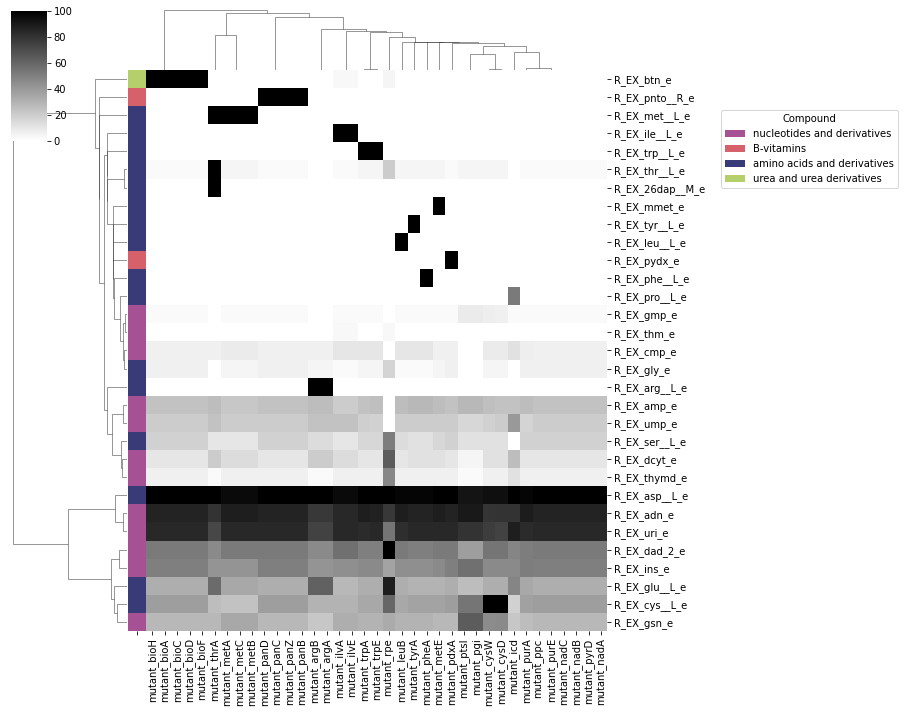

In [ ]:


g = sns.clustermap(minimal_media_df_ecoli_plot,
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_bigg,
                   xticklabels=1,
                   yticklabels=1)

relevant_classes = list(set([biggEx2chebi[key] for key in minimal_media_df_ecoli_plot.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Compound',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)


**Find experimental results for top 7 members**

In [31]:
RA_ecoli_mean = relative_abundance_ecoli.T.mean().sort_values(ascending=False)
RA_ecoli_mean[RA_ecoli_mean>0.01]

icd     0.287848
panZ    0.276678
bioH    0.211130
bioF    0.098526
cysW    0.062219
bioC    0.020200
panD    0.015948
dtype: float64

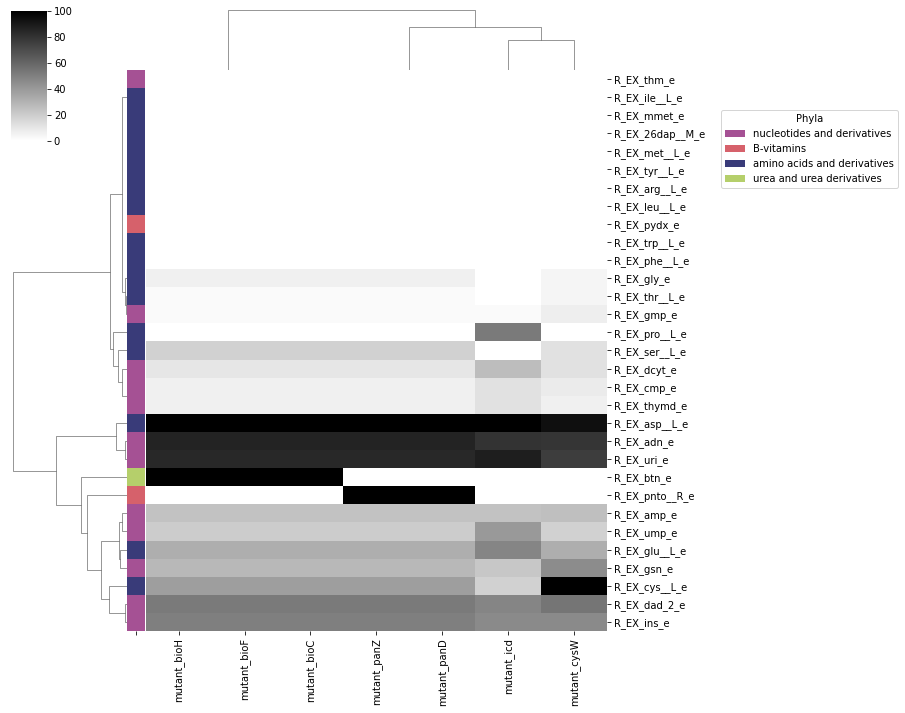

In [33]:
relevant_ecoli_mutants = RA_ecoli_mean[RA_ecoli_mean>0.01].index
relevant_ecoli_mutants = ["mutant_" + mutant for mutant in relevant_ecoli_mutants]
minimal_media_df_ecoli_plot2 = minimal_media_df_ecoli_plot.loc[:,minimal_media_df_ecoli_plot.columns.isin(relevant_ecoli_mutants)]

g = sns.clustermap(minimal_media_df_ecoli_plot2,
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_bigg,
                   xticklabels=1)

relevant_classes = list(set([biggEx2chebi[key] for key in minimal_media_df_ecoli_plot2.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Phyla',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)

#### Members of gut microbiome

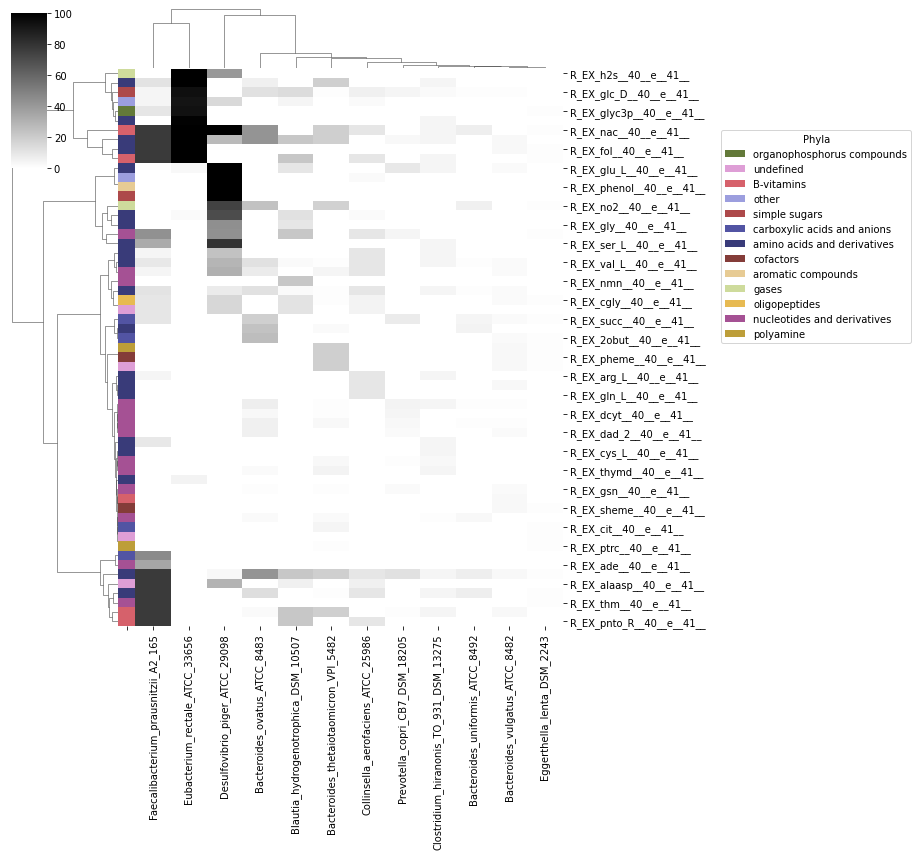

In [34]:
g = sns.clustermap(minimal_media_df_gut_plot,
                   figsize=(10,12),
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_agora,
                   xticklabels=1)

relevant_classes = list(set([agoraEx2chebi[key] for key in minimal_media_df_gut_plot.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Phyla',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)

#g.savefig("figures_meeting/minimal_medium_gut.png")

## Auxotrophies

### E. coli mutants

In [36]:
auxotrophies_ecoli = {}
for model_id,model in models_ecoli.items():
    print(f"Started analysis for {model_id}")
    model_copy = model.copy()
    constraints = {rxn:(0,1000) for rxn in model_copy.get_exchange_reactions()}
    
    rxns_env = [rxn.replace("91","40").replace("93","41") for rxn in env_ecoli_lb.keys()]
    constraints_env = {rxn: (-10,1000) for rxn in rxns_env if rxn in model_copy.reactions}
    constraints.update(constraints_env)
    auxotrophies_spec = auxotrophy.auxotrophies(model_copy,constraints=constraints)
    if not auxotrophies_spec:
        continue
    for aux in auxotrophies_spec:
        auxotrophies_ecoli[(model_id,aux)]=1

Started analysis for mutant_trpA
Started analysis for mutant_pyrD
Started analysis for mutant_panZ
Started analysis for mutant_trpE
Started analysis for mutant_pheA
Started analysis for mutant_pdxA
Started analysis for mutant_leuB
Started analysis for mutant_bioD
Started analysis for mutant_argB
Started analysis for mutant_tyrA
Started analysis for mutant_bioF
Started analysis for mutant_argA
Started analysis for mutant_bioC
Started analysis for mutant_ptsI
Started analysis for mutant_bioA
Started analysis for mutant_icd
Started analysis for mutant_thrA
Started analysis for mutant_bioH
Started analysis for mutant_nadA
Started analysis for mutant_panB
Started analysis for mutant_metE
Started analysis for mutant_panC
Started analysis for mutant_ilvA
Started analysis for mutant_aroC


/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/cobra/auxotrophy.py:18: UserWarning: Organism does not grow in given medium.
  warn("Organism does not grow in given medium.")


Started analysis for mutant_nadB
Started analysis for mutant_rpe
Started analysis for mutant_cysW
Started analysis for mutant_purA
Started analysis for mutant_nadC
Started analysis for mutant_purE
Started analysis for mutant_cysD
Started analysis for mutant_panD
Started analysis for mutant_metC
Started analysis for mutant_ppc
Started analysis for mutant_metB
Started analysis for mutant_ilvE
Started analysis for mutant_metA
Started analysis for mutant_pgi


In [37]:
auxotrophies_ecoli_df = pd.Series(auxotrophies_ecoli).unstack().fillna(0).T
auxotrophies_ecoli_df = auxotrophies_ecoli_df.loc[auxotrophies_ecoli_df.T.sum()!=len(auxotrophies_ecoli_df.columns)]

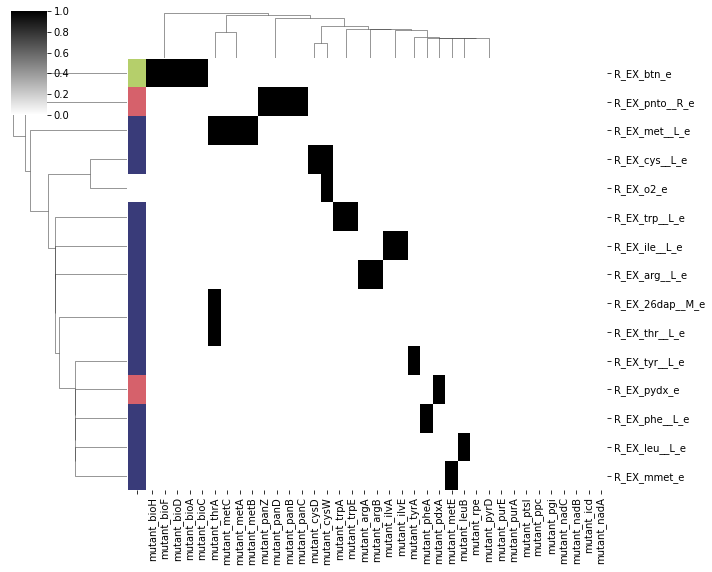

In [38]:
g = sns.clustermap(auxotrophies_ecoli_df,
                   figsize=(10,8),
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_bigg,
                   yticklabels=1,
                   xticklabels=1)

### Gut microbiome

In [39]:
auxotrophies_gut = {}
for model_id,model in models_gut.items():
    print(f"Started analysis for {model_id}")
    model_copy = model.copy()

    rxns_env = env_gut_single.keys()
    constraints = {rxn:(0,1000) for rxn in model_copy.get_exchange_reactions()}
    constraints_env = {rxn: (-1,1000) for rxn in rxns_env if rxn in model_copy.reactions}
    constraints.update(constraints_env)
    auxotrophies_spec = auxotrophy.auxotrophies(model_copy,constraints=constraints)
    
    for aux in auxotrophies_spec:
        auxotrophies_gut[(model_id,aux)]=1

Started analysis for Bacteroides_uniformis_ATCC_8492
Started analysis for Bacteroides_vulgatus_ATCC_8482
Started analysis for Collinsella_aerofaciens_ATCC_25986
Started analysis for Faecalibacterium_prausnitzii_A2_165
Started analysis for Eggerthella_lenta_DSM_2243
Started analysis for Prevotella_copri_CB7_DSM_18205
Started analysis for Clostridium_hiranonis_TO_931_DSM_13275
Started analysis for Eubacterium_rectale_ATCC_33656
Started analysis for Desulfovibrio_piger_ATCC_29098
Started analysis for Bacteroides_ovatus_ATCC_8483
Started analysis for Bacteroides_thetaiotaomicron_VPI_5482
Started analysis for Blautia_hydrogenotrophica_DSM_10507


In [40]:
auxotrophies_gut_df = pd.Series(auxotrophies_gut).unstack().fillna(0).T
auxotrophies_gut_df = auxotrophies_gut_df.loc[auxotrophies_gut_df.T.sum()!=len(auxotrophies_gut_df.columns)]


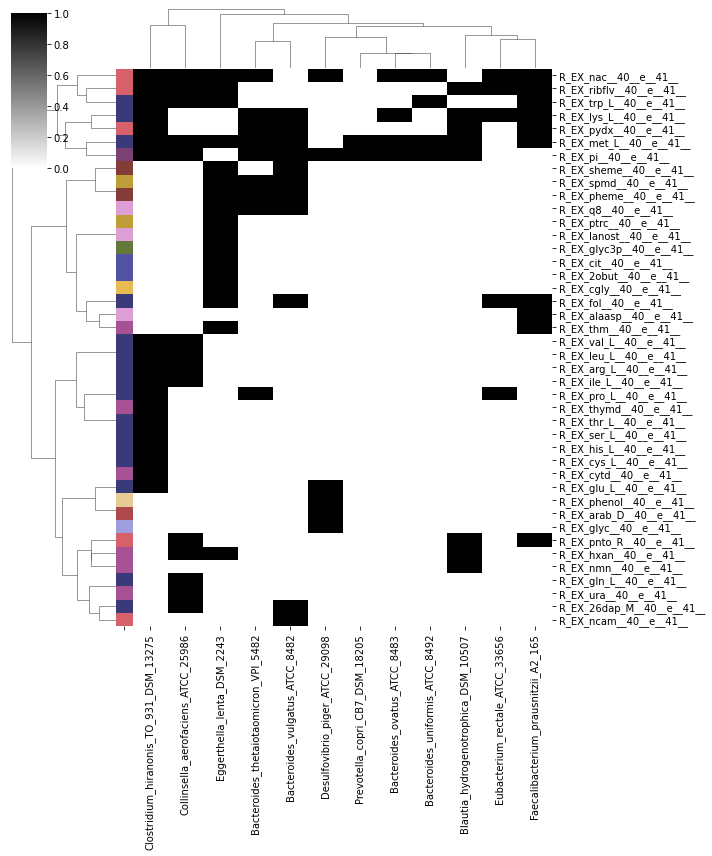

In [41]:
g = sns.clustermap(auxotrophies_gut_df,
                   figsize=(10,12),
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_agora,
                   xticklabels=1)

In [42]:
auxotrophies_ecoli_df_stack = auxotrophies_ecoli_df.T.stack()

auxotrophies_ecoli_df_stack = auxotrophies_ecoli_df_stack[auxotrophies_ecoli_df_stack!=0].sort_index()
auxotrophies_ecoli_df_stack.index.names = ["member","compound"]
auxotrophies_ecoli_df_stack.to_csv("../output/Guillen2021/auxotrophies.tsv",sep="\t")

In [43]:
auxotrophies_gut_df_stack = auxotrophies_gut_df.T.stack()

auxotrophies_gut_df_stack = auxotrophies_gut_df_stack[auxotrophies_gut_df_stack!=0].sort_index()
auxotrophies_gut_df_stack.index.names = ["member","compound"]
auxotrophies_gut_df_stack.to_csv("../output/Venturelli2018/auxotrophies.tsv",sep="\t")

## Check community growth

**Load media**

*For E. coli mutants (M9 medium to see if they can grow together)*

In [44]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = list(media_db[media_db.medium=="M9"].compound.values)
env_ecoli_m9 = reframed.Environment.from_compounds(compounds,max_uptake=50)

*For gut microbiome members*

In [45]:
media_db_gut = pd.read_csv("../data/Venturelli2018/generated/media_db.tsv",sep="\t")
reactions = media_db_gut[media_db_gut.medium=="LB_extend"].compound.values
env_gut_community = reframed.Environment.from_reactions(reactions,max_uptake=10)

### Check community growth

**Make community model**

*For E. coli mutants*

In [46]:
comm_ecoli = reframed.Community(models=models_ecoli_top7.values(),community_id="ecoli_mutants")

*For gut microbiome members*

In [47]:
comm_gut = reframed.Community(models=models_gut.values(),community_id="gut_microbiome")

#### Ecoli mutants community growth

In [48]:
env_ecoli_m9.apply(comm_ecoli.merged_model, inplace=True, exclusive=True, warning=False)

biomass_rxns = comm_ecoli.merged_model.get_metabolite_producers("community_biomass")
growth = np.ones(len(biomass_rxns))*0.1
growth_upper = np.ones(len(biomass_rxns))*1000
constraints_growth_ecoli = dict(zip(biomass_rxns,list(zip(growth,growth_upper))))

In [49]:
sol = reframed.FBA(comm_ecoli.merged_model,
                   constraints=constraints_growth_ecoli
                  )
sol.values["community_growth"]

2.5413888975782113

In [50]:
for rxn in biomass_rxns:
    print(f"{rxn}: {sol.values[rxn]}")

R_BIOMASS_Ec_iML1515_core_75p37M_mutant_panZ: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioF: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioC: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_icd: 1.9413888975782114
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioH: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_cysW: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_panD: 0.1


#### Gut microbiome community growth

In [51]:
env_gut_community.apply(comm_gut.merged_model, inplace=True, exclusive=True, warning=False)

biomass_rxns = comm_gut.merged_model.get_metabolite_producers("community_biomass")
growth = np.ones(len(biomass_rxns))*0.1
growth_upper = np.ones(len(biomass_rxns))*1000
constraints_growth_gut = dict(zip(biomass_rxns,list(zip(growth,growth_upper))))

In [52]:
sol = reframed.FBA(comm_gut.merged_model,constraints=constraints_growth_gut)

sol.values["community_growth"]

5.624786739546615

In [53]:
for rxn in biomass_rxns:
    print(f"{rxn}: {sol.values[rxn]}")

R_biomass536_M_Bacteroides_uniformis_ATCC_8492: 0.1
R_biomass345_M_Bacteroides_vulgatus_ATCC_8482: 0.1
R_biomass524_M_Collinsella_aerofaciens_ATCC_25986: 0.1
R_biomass223_M_Faecalibacterium_prausnitzii_A2_165: 1.8573385407571488
R_biomass467_M_Eggerthella_lenta_DSM_2243: 2.0536547484715553
R_biomass525_M_Prevotella_copri_CB7_DSM_18205: 0.1
R_biomass525_M_Clostridium_hiranonis_TO_931_DSM_13275: 0.1
R_biomass205_M_Eubacterium_rectale_ATCC_33656: 0.1
R_biomass525_M_Desulfovibrio_piger_ATCC_29098: 0.1
R_biomass536_M_Bacteroides_ovatus_ATCC_8483: 0.1
R_biomass345_M_Bacteroides_thetaiotaomicron_VPI_5482: 0.8137934503179116
R_biomass525_M_Blautia_hydrogenotrophica_DSM_10507: 0.1
